# Final model validation analysis
Explore the saved walk-forward predictions from `python run.py validate`. This notebook **does not fit models**. Run all cells after validation finishes to refresh the analysis.

Both tracks are scored separately. Lower MAPE, MdAPE, and P90 absolute error are better; positive signed error means overprediction. These are held-out diagnostics, not a reason to retune weights on the verification months.

The CSV does not store model identity or a code fingerprint. Confirm it came from your intended final model; changing `run.py` later does not update saved predictions.

In [1]:
from pathlib import Path
from datetime import datetime
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'run.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the project folder.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import data

PREDICTIONS_FILE = ROOT / 'outputs' / 'validation_predictions.csv'
EXPORT_DIR = ROOT / 'reports' / 'final_model_analysis'
MIN_GROUP_SIZE = 30
MAP_MIN_COUNT = 5
SAVE_OUTPUTS = True
COLORS = {'off_market': '#2878B5', 'list_aware': '#D97536'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 12, 'axes.labelsize': 10})

def finish(fig, filename):
    fig.tight_layout()
    if SAVE_OUTPUTS:
        EXPORT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(EXPORT_DIR / (filename + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## Load predictions and attach location metadata
The join must be many predictions to one listing (one prediction per track and home). Prices and sale months are checked against the source listings so mismatched files cannot silently produce location charts.

In [10]:
if not PREDICTIONS_FILE.exists():
    raise FileNotFoundError(f'{PREDICTIONS_FILE} is missing. Run python run.py validate first.')
predictions = pd.read_csv(PREDICTIONS_FILE, dtype={'ml_num': 'string', 'track': 'string', 'month': 'string'})
required = {'ml_num', 'track', 'month', 'sold_price', 'predicted_price', 'house_type_name'}
if missing := required - set(predictions):
    raise ValueError(f'Missing prediction columns: {sorted(missing)}')
if predictions.empty or predictions[['ml_num', 'track', 'month']].isna().any().any():
    raise ValueError('Predictions must contain rows and nonmissing identifiers.')
if predictions.duplicated(['track', 'ml_num']).any():
    raise ValueError('Duplicate home predictions within a track.')
if not set(predictions.track) <= set(COLORS):
    raise ValueError('Unexpected prediction track.')
for column in ['sold_price', 'predicted_price']:
    predictions[column] = pd.to_numeric(predictions[column], errors='raise')
    if not (np.isfinite(predictions[column]) & predictions[column].gt(0)).all():
        raise ValueError(f'{column} must be positive and finite.')

listings = data.load('listings')
metadata = listings[['ml_num', 'municipality', 'community', 'latitude', 'longitude', 'date_sold', 'sold_price']].copy()
metadata['ml_num'] = metadata.ml_num.astype('string')
metadata = metadata.rename(columns={'sold_price': 'source_sold_price'})
if metadata.ml_num.isna().any() or metadata.ml_num.duplicated().any():
    raise ValueError('Listing IDs must be unique and nonmissing for a safe join.')
results = predictions.merge(metadata, on='ml_num', how='left', validate='many_to_one', indicator=True)
if not results['_merge'].eq('both').all():
    raise ValueError('Some predictions have no matching listing. Check the data source.')
if not np.allclose(results.sold_price, results.source_sold_price, rtol=0, atol=.01):
    raise ValueError('Saved sale prices disagree with the source listings.')
if not results.month.eq(results.date_sold.dt.to_period('M').astype(str)).all():
    raise ValueError('Saved validation months disagree with listing sale dates.')
results = results.drop(columns=['_merge', 'source_sold_price'])
for column in ['house_type_name', 'municipality', 'community']:
    results[column] = results[column].fillna('Unknown').astype(str).str.strip().replace('', 'Unknown')
results['error_dollars'] = results.predicted_price - results.sold_price
results['signed_error_pct'] = 100 * results.error_dollars / results.sold_price
results['ape_pct'] = results.signed_error_pct.abs()
TRACKS = [t for t in COLORS if t in set(results.track)]
print(f'Source: {PREDICTIONS_FILE.relative_to(ROOT)}')
print(f'File modified (local time): {datetime.fromtimestamp(PREDICTIONS_FILE.stat().st_mtime):%Y-%m-%d %H:%M:%S}')
print(f'{len(results):,} predictions; {results.ml_num.nunique():,} unique homes; {results.month.min()} to {results.month.max()}')
coverage = pd.crosstab(results.month, results.track)
display(coverage)
if len(TRACKS) != 2 or coverage.eq(0).any().any():
    print('NOTE: One or more track/month combinations are missing.')
if len(TRACKS) == 2:
    ids = [set(results.loc[results.track.eq(t), 'ml_num']) for t in TRACKS]
    if ids[0] != ids[1]:
        print('NOTE: Tracks cover different homes; comparisons are not fully paired.')

Source: outputs\validation_predictions.csv
File modified (local time): 2026-11-07 16:44:47
20,138 predictions; 10,069 unique homes; 2025-12 to 2026-05


track,list_aware,off_market
month,,
2025-12,1238,1238
2026-01,1058,1058
2026-02,1442,1442
2026-03,1816,1816
2026-04,2224,2224
2026-05,2291,2291


## Overall performance
MAPE is mean absolute percentage error; MdAPE is median absolute percentage error; P90 is its 90th percentile. MAE and RMSE are in dollars. Within 10% and 20% report the percentage of predictions meeting those thresholds. All metrics use every saved prediction; plotting limits below never remove observations from scores.

,track,n,mape_pct,mdape_pct,p90_ape_pct,median_bias_pct,mae_dollars,rmse_dollars,within_10_pct,within_20_pct
0,list_aware,10069,4.96,3.90,10.44,0.3,56919.36,106471.34,88.91,99.00
1,off_market,10069,9.53,7.13,20.25,0.3,117381.40,273930.82,64.67,89.63


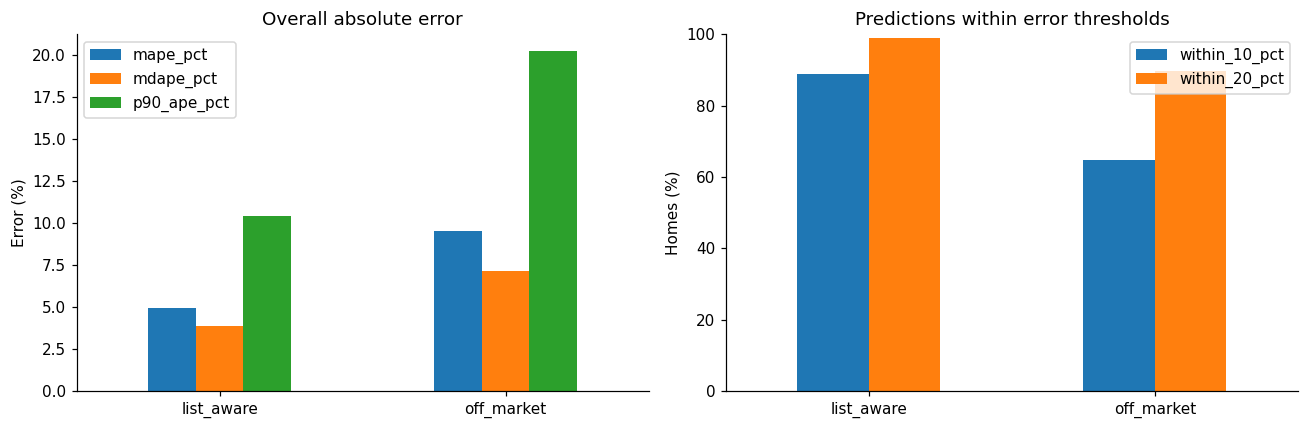

In [11]:
def summarize(frame, groups):
    return frame.groupby(groups, observed=True, dropna=False).agg(
        n=('ape_pct', 'size'),
        mape_pct=('ape_pct', 'mean'),
        mdape_pct=('ape_pct', 'median'),
        p90_ape_pct=('ape_pct', lambda x: x.quantile(.9)),
        median_bias_pct=('signed_error_pct', 'median'),
        mae_dollars=('error_dollars', lambda x: x.abs().mean()),
        rmse_dollars=('error_dollars', lambda x: np.sqrt(np.mean(np.square(x)))),
        within_10_pct=('ape_pct', lambda x: 100 * x.le(10).mean()),
        within_20_pct=('ape_pct', lambda x: 100 * x.le(20).mean()),
    ).reset_index()

scores = summarize(results, ['track'])
display(scores.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
scores.set_index('track')[['mape_pct', 'mdape_pct', 'p90_ape_pct']].plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Overall absolute error', ylabel='Error (%)', xlabel='')
scores.set_index('track')[['within_10_pct', 'within_20_pct']].plot.bar(ax=axes[1], rot=0)
axes[1].set(title='Predictions within error thresholds', ylabel='Homes (%)', ylim=(0, 100), xlabel='')
finish(fig, 'overall_performance')

## Property type and municipality
Bars show median absolute percentage error; labels include sample counts. Groups below `MIN_GROUP_SIZE` are omitted from these charts but retained in exported tables. Municipality charts use the 15 most common municipalities, not the 15 worst errors.

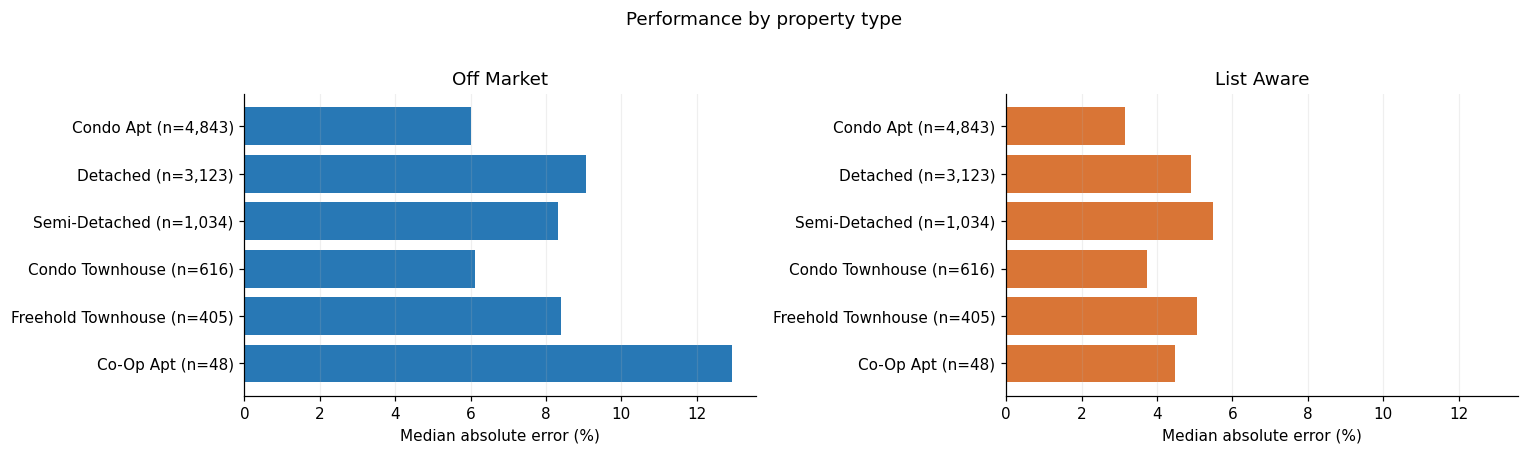

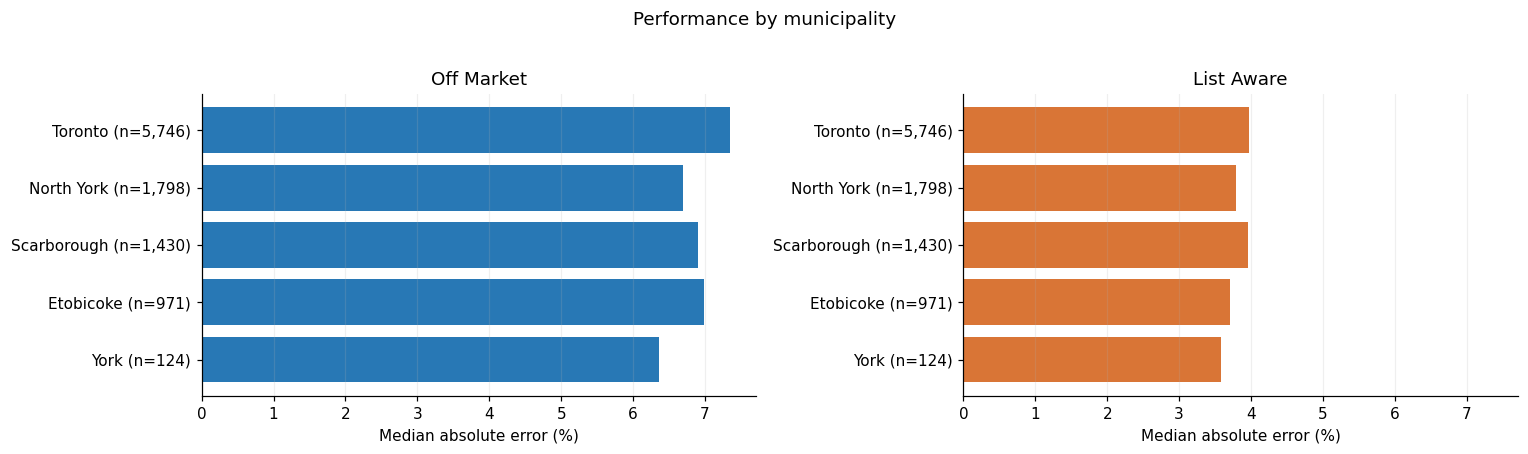

,track,house_type_name,n,mape_pct,mdape_pct,p90_ape_pct,median_bias_pct,mae_dollars,rmse_dollars,within_10_pct,within_20_pct
0,list_aware,Co-Op Apt,48,4.75,4.48,10.01,0.68,39043.04,68612.60,89.58,100.00
1,list_aware,Condo Apt,4843,3.76,3.15,7.66,0.45,23160.91,31402.24,96.76,99.98
2,list_aware,Condo Townhouse,616,4.71,3.74,10.04,0.48,35709.44,49658.37,89.61,99.84
3,list_aware,Detached,3123,6.19,4.91,13.12,0.28,101933.54,167608.49,81.20,97.82
4,list_aware,Freehold Townhouse,405,6.36,5.07,13.31,-0.15,80440.12,116196.48,79.26,97.28
5,list_aware,Semi-Detached,1034,6.51,5.48,13.61,-1.19,83331.75,118099.08,78.72,98.07
6,off_market,Co-Op Apt,48,18.32,12.93,38.86,-1.01,287538.54,851853.43,41.67,75.00
7,off_market,Condo Apt,4843,8.22,6.01,17.12,1.22,58238.39,133376.86,72.37,93.08
8,off_market,Condo Townhouse,616,7.59,6.13,16.09,0.83,57457.50,85670.72,73.54,94.16
9,off_market,Detached,3123,11.47,9.06,23.96,-0.42,208783.55,425419.88,54.18,84.31


Communities with the highest median error (among groups meeting the sample threshold):


,track,municipality,community,n,mape_pct,mdape_pct,p90_ape_pct,median_bias_pct,mae_dollars,rmse_dollars,within_10_pct,within_20_pct
258,off_market,Toronto,Maplepark,36,21.36,15.70,47.40,-3.14,939546.44,1471576.07,27.78,61.11
192,off_market,Scarborough,Hazelfield,68,15.87,14.73,30.06,-4.69,539252.25,933105.38,38.24,72.06
282,off_market,Toronto,Sycamorewood,34,12.14,13.91,24.16,2.55,106662.18,139731.48,44.12,82.35
269,off_market,Toronto,Rowanhollow,29,14.92,13.77,29.54,-6.42,381357.66,594658.20,37.93,68.97
150,off_market,Etobicoke,Cypressglen,54,16.35,13.70,32.47,2.62,104814.48,170628.79,38.89,79.63
215,off_market,Toronto,Beechcrest,28,15.85,13.40,30.14,1.19,456347.21,624953.34,46.43,71.43
275,off_market,Toronto,Sumacfield,52,12.29,12.45,23.31,3.64,134648.29,206918.96,46.15,80.77
286,off_market,Toronto,Willowpark,58,14.29,12.17,30.38,3.53,555942.81,1261529.20,39.66,75.86
207,off_market,Toronto,Alderhaven,8,15.19,12.05,27.15,-6.87,154120.38,166189.31,37.50,75.00
233,off_market,Toronto,Dogwoodglen,24,13.91,11.56,21.44,-3.01,128721.75,161202.66,41.67,87.50


In [17]:
property_scores = summarize(results, ['track', 'house_type_name'])
municipality_scores = summarize(results, ['track', 'municipality'])
community_scores = summarize(results, ['track', 'municipality', 'community'])
MIN_GROUP_SIZE = 0
def group_chart(table, group, title, filename, limit=None):
    eligible = table.loc[table.n.ge(MIN_GROUP_SIZE)]
    order = eligible.groupby(group).n.sum().sort_values(ascending=False).index
    if limit:
        order = order[:limit]
    fig, axes = plt.subplots(1, len(TRACKS), figsize=(7 * len(TRACKS), max(4, len(order) * .4)), squeeze=False)
    for ax, track in zip(axes[0], TRACKS):
        rows = eligible.loc[eligible.track.eq(track)].set_index(group).reindex(order).dropna(subset=['n'])
        ax.barh(np.arange(len(rows)), rows.mdape_pct, color=COLORS[track])
        ax.set_yticks(np.arange(len(rows)), [f'{name} (n={int(n):,})' for name, n in zip(rows.index, rows.n)])
        ax.invert_yaxis()
        ax.set(title=track.replace('_', ' ').title(), xlabel='Median absolute error (%)')
        ax.grid(axis='x', alpha=.2)
    limits = [ax.get_xlim()[1] for ax in axes[0]]
    for ax in axes[0]:
        ax.set_xlim(0, max(limits))
    fig.suptitle(title, y=1.02)
    finish(fig, filename)

group_chart(property_scores, 'house_type_name', 'Performance by property type', 'property_type')
group_chart(municipality_scores, 'municipality', 'Performance by municipality', 'municipality', limit=15)
display(property_scores.round(2))
print('Communities with the highest median error (among groups meeting the sample threshold):')
display(community_scores.loc[community_scores.n.ge(MIN_GROUP_SIZE)].sort_values('mdape_pct', ascending=False).head(20).round(2))

## Month, price range, and error distribution
Price bands use actual sale prices and identical boundaries across tracks. Distribution charts display the central 99% of absolute errors for readability; their titles report the number outside the displayed range.

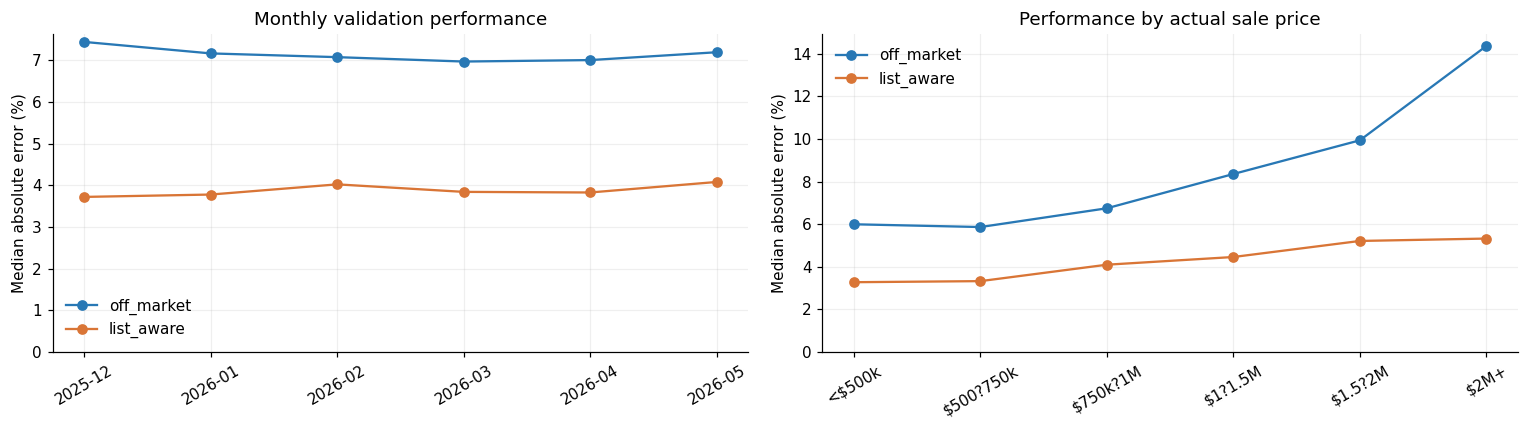

,track,price_band,n,mape_pct,mdape_pct,p90_ape_pct,median_bias_pct,mae_dollars,rmse_dollars,within_10_pct,within_20_pct
0,list_aware,<$500k,1743,4.05,3.28,8.28,1.37,16873.81,21543.89,95.47,99.89
1,list_aware,$500?750k,2811,4.06,3.33,8.33,0.60,25179.00,32789.30,94.24,99.82
2,list_aware,$750k?1M,1883,4.99,4.10,10.36,0.33,43564.28,56733.76,88.90,99.36
3,list_aware,$1?1.5M,2147,5.68,4.46,12.12,-0.66,68921.11,90479.84,83.47,98.70
4,list_aware,$1.5?2M,766,6.47,5.21,13.81,-1.37,110793.16,143881.76,80.29,97.00
5,list_aware,$2M+,719,6.89,5.33,15.49,-1.11,219831.90,313837.70,77.61,95.69
6,off_market,<$500k,1743,8.20,6.00,16.47,4.61,33205.64,49906.55,72.46,93.69
7,off_market,$500?750k,2811,7.83,5.87,16.81,1.34,48514.73,70069.23,74.53,93.38
8,off_market,$750k?1M,1883,8.84,6.75,18.31,0.35,76582.41,110351.64,67.07,91.93
9,off_market,$1?1.5M,2147,10.13,8.36,20.40,-3.03,123371.53,163491.86,58.36,89.38


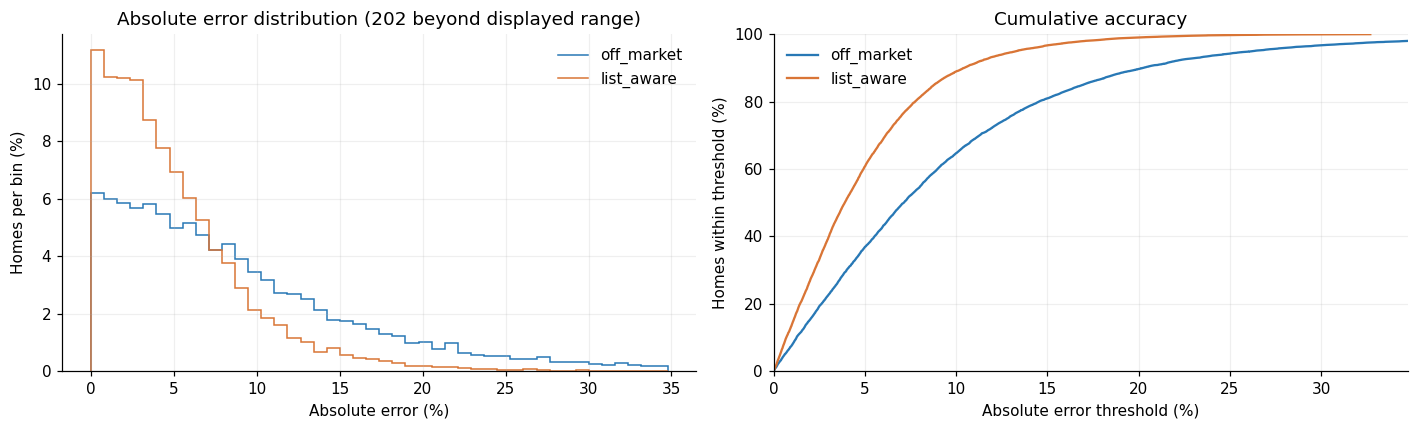

In [13]:
monthly_scores = summarize(results, ['track', 'month'])
results['price_band'] = pd.cut(results.sold_price, [0, 500_000, 750_000, 1_000_000, 1_500_000, 2_000_000, np.inf],
    labels=['<$500k', '$500?750k', '$750k?1M', '$1?1.5M', '$1.5?2M', '$2M+'], right=False)
price_scores = summarize(results, ['track', 'price_band'])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for track in TRACKS:
    rows = monthly_scores.loc[monthly_scores.track.eq(track)]
    axes[0].plot(rows.month, rows.mdape_pct, marker='o', color=COLORS[track], label=track)
    rows = price_scores.loc[price_scores.track.eq(track)]
    axes[1].plot(rows.price_band.astype(str), rows.mdape_pct, marker='o', color=COLORS[track], label=track)
for ax, title in zip(axes, ['Monthly validation performance', 'Performance by actual sale price']):
    ax.set(title=title, ylabel='Median absolute error (%)', ylim=(0, None))
    ax.tick_params(axis='x', rotation=30)
    ax.grid(alpha=.2)
    ax.legend(frameon=False)
finish(fig, 'month_and_price')
display(price_scores.round(2))

cap = max(1, float(results.ape_pct.quantile(.99)))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for track in TRACKS:
    rows = results.loc[results.track.eq(track)]
    counts, bins = np.histogram(rows.ape_pct, bins=np.linspace(0, cap, 45))
    axes[0].stairs(100 * counts / len(rows), bins, label=track, color=COLORS[track])
    ordered = np.sort(rows.ape_pct.to_numpy())
    axes[1].plot(ordered, 100 * np.arange(1, len(ordered) + 1) / len(ordered), label=track, color=COLORS[track])
axes[0].set(title=f'Absolute error distribution ({results.ape_pct.gt(cap).sum():,} beyond displayed range)', xlabel='Absolute error (%)', ylabel='Homes per bin (%)')
axes[1].set(title='Cumulative accuracy', xlabel='Absolute error threshold (%)', ylabel='Homes within threshold (%)', xlim=(0, cap), ylim=(0, 100))
for ax in axes:
    ax.legend(frameon=False)
    ax.grid(alpha=.2)
finish(fig, 'error_distribution')

## Geographic performance maps
These offline maps use the supplied latitude/longitude without downloading map tiles. The first map aggregates homes into hexagons and shows median absolute error; bins with fewer than `MAP_MIN_COUNT` homes are hidden. The second shows individual overpredictions (red) and underpredictions (blue).

Both tracks use the same extent and color limits. Colors saturate at the pooled 95th-percentile error; outliers remain in the maps and all metrics. Coordinates are plotted as supplied, so interpret geography with any anonymization in the dataset in mind.

Mapped 20,138/20,138 predictions; 0 missing/invalid locations excluded only from maps.


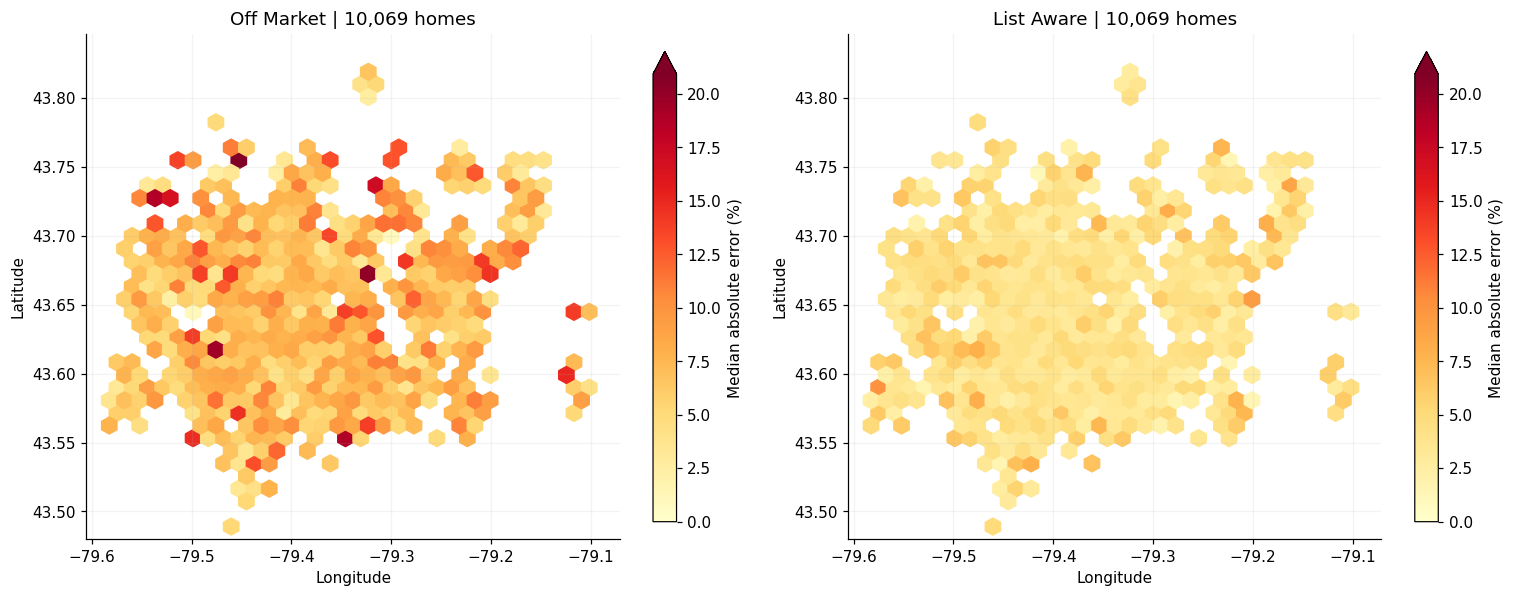

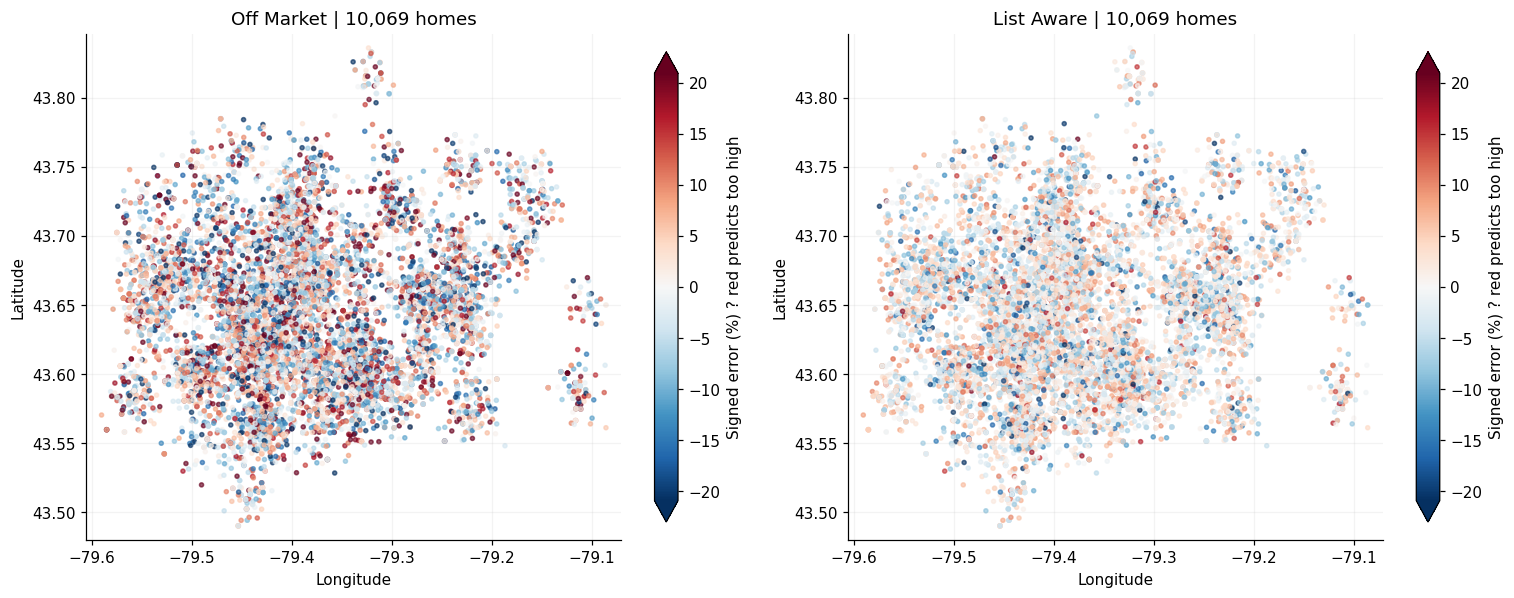

In [14]:
for column in ['latitude', 'longitude']:
    results[column] = pd.to_numeric(results[column], errors='coerce')
valid_geo = (np.isfinite(results.latitude) & np.isfinite(results.longitude)
             & results.latitude.between(-90, 90) & results.longitude.between(-180, 180))
geo = results.loc[valid_geo].copy()
print(f'Mapped {len(geo):,}/{len(results):,} predictions; {len(results) - len(geo):,} missing/invalid locations excluded only from maps.')
if geo.empty:
    print('No valid coordinates are available.')
else:
    lon_min, lon_max = geo.longitude.min(), geo.longitude.max()
    lat_min, lat_max = geo.latitude.min(), geo.latitude.max()
    lon_pad = max((lon_max - lon_min) * .03, .001)
    lat_pad = max((lat_max - lat_min) * .03, .001)
    extent = (lon_min - lon_pad, lon_max + lon_pad, lat_min - lat_pad, lat_max + lat_pad)
    color_cap = max(1, float(geo.ape_pct.quantile(.95)))
    aspect = 1 / max(.01, np.cos(np.deg2rad(geo.latitude.mean())))
    for mode in ['absolute', 'signed']:
        fig, axes = plt.subplots(1, len(TRACKS), figsize=(7 * len(TRACKS), 6), squeeze=False)
        for ax, track in zip(axes[0], TRACKS):
            rows = geo.loc[geo.track.eq(track)]
            if mode == 'absolute':
                ax.hexbin(rows.longitude, rows.latitude, C=rows.ape_pct, gridsize=35,
                          extent=extent, reduce_C_function=np.median, mincnt=MAP_MIN_COUNT,
                          cmap='YlOrRd', norm=Normalize(0, color_cap))
            else:
                ax.scatter(rows.longitude, rows.latitude, c=rows.signed_error_pct,
                           s=7, alpha=.65, cmap='RdBu_r', norm=Normalize(-color_cap, color_cap), rasterized=True)
            ax.set(xlim=extent[:2], ylim=extent[2:], xlabel='Longitude', ylabel='Latitude',
                   title=f'{track.replace("_", " ").title()} | {len(rows):,} homes')
            ax.set_aspect(aspect)
            ax.grid(alpha=.15)
        norm = Normalize(0, color_cap) if mode == 'absolute' else Normalize(-color_cap, color_cap)
        label = 'Median absolute error (%)' if mode == 'absolute' else 'Signed error (%) ? red predicts too high'
        for ax in axes[0]:
            fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap='YlOrRd' if mode == 'absolute' else 'RdBu_r'), ax=ax,
                         shrink=.75, label=label, extend='max' if mode == 'absolute' else 'both')
        finish(fig, f'location_{mode}_error')

## Interactive location map
Hover to inspect a home's property type, municipality, actual price, prediction, and error. Set `MAP_TRACK` to choose a track. Plotly is optional; the static maps above work without it. Street-map tiles require internet access when viewing the map; use `MAP_STYLE = "white-bg"` for points on an offline background.

In [15]:
MAP_TRACK = 'off_market'
MAP_STYLE = 'carto-positron'
try:
    import plotly.express as px
except ImportError:
    print('Optional interactive map skipped: install plotly in this notebook environment to enable it.')
else:
    mapped = geo.loc[geo.track.eq(MAP_TRACK)].copy()
    if mapped.empty:
        print(f'No locations available for {MAP_TRACK}.')
    else:
        map_cap = max(1, float(geo.ape_pct.quantile(.95)))
        map_figure = px.scatter_map(mapped, lat='latitude', lon='longitude', color='ape_pct',
            color_continuous_scale='YlOrRd', range_color=(0, map_cap),
            hover_name='ml_num', hover_data={'house_type_name': True, 'municipality': True,
                'community': True, 'sold_price': ':,.0f', 'predicted_price': ':,.0f',
                'ape_pct': ':.2f', 'signed_error_pct': ':.2f', 'month': True,
                'latitude': False, 'longitude': False},
            labels={'ape_pct': 'Absolute error (%)', 'signed_error_pct': 'Signed error (%)'},
            center={'lat': mapped.latitude.median(), 'lon': mapped.longitude.median()},
            zoom=9, map_style=MAP_STYLE, height=650,
            title=f'{MAP_TRACK}: validation error by location')
        map_figure.update_traces(marker={'size': 6, 'opacity': .7})
        map_figure.show()
        if SAVE_OUTPUTS:
            EXPORT_DIR.mkdir(parents=True, exist_ok=True)
            map_figure.write_html(EXPORT_DIR / f'location_interactive_{MAP_TRACK}.html', include_plotlyjs=True)

## Inspect large errors and export results
Large percentage errors can be driven by low sale prices or unusual properties; inspect the underlying rows before drawing conclusions. Tables retain small groups even when charts hide them. The existing prediction CSV and model files are never modified.

In [16]:
columns = ['ml_num', 'track', 'month', 'house_type_name', 'municipality', 'community',
           'sold_price', 'predicted_price', 'signed_error_pct', 'ape_pct']
display(results.nlargest(20, 'ape_pct')[columns].round(2))
if SAVE_OUTPUTS:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    tables = {'overall': scores, 'by_property_type': property_scores, 'by_municipality': municipality_scores,
              'by_community': community_scores, 'by_month': monthly_scores, 'by_price_band': price_scores,
              'prediction_diagnostics': results}
    for name, table in tables.items():
        table.to_csv(EXPORT_DIR / f'{name}.csv', index=False)
    print(f'Figures, tables, and interactive map saved to {EXPORT_DIR.relative_to(ROOT)}')

,ml_num,track,month,house_type_name,municipality,community,sold_price,predicted_price,signed_error_pct,ape_pct
7628,SYN-0138680,off_market,2026-03,Condo Apt,North York,Tamarackmills,226200.0,739518.0,226.93,226.93
17344,SYN-0031235,off_market,2026-05,Detached,Toronto,Juniperheights,892200.0,2786580.0,212.33,212.33
8932,SYN-0101164,off_market,2026-03,Condo Apt,Toronto,Beechglen,551900.0,1228905.0,122.67,122.67
17002,SYN-0087681,off_market,2026-05,Co-Op Apt,Toronto,Hemlockvale,434400.0,944965.0,117.53,117.53
8181,SYN-0083582,off_market,2026-03,Condo Apt,Toronto,Rowanbrook,418100.0,879910.0,110.45,110.45
1120,SYN-0042294,off_market,2025-12,Condo Apt,Etobicoke,Cypressglen,354700.0,727249.0,105.03,105.03
3081,SYN-0150751,off_market,2026-01,Condo Apt,Toronto,Elmview,686300.0,1360860.0,98.29,98.29
8639,SYN-0061334,off_market,2026-03,Condo Apt,Toronto,Sumacwood,240300.0,464644.0,93.36,93.36
7696,SYN-0065135,off_market,2026-03,Detached,Toronto,Hemlockvale,1061500.0,2037037.0,91.90,91.90
4860,SYN-0072598,off_market,2026-02,Co-Op Apt,Toronto,Hickoryhaven,5816500.0,985019.0,-83.07,83.07


Figures, tables, and interactive map saved to reports\final_model_analysis


## Effective weights of all final ensemble members
The final blend and `ensemble_method` both combine predictions geometrically. Each submember's effective weight is therefore **its normalized internal weight multiplied by the normalized team weight of ensemble_method**. The two standalone contributions retain their team weights.

These are coefficients in the final **log-price blend**, not feature importance or shares of predictive accuracy. Colors identify the three code contributions. Values are read from the current frozen weights and checkpoint summaries; the prediction CSV does not record historical weights.

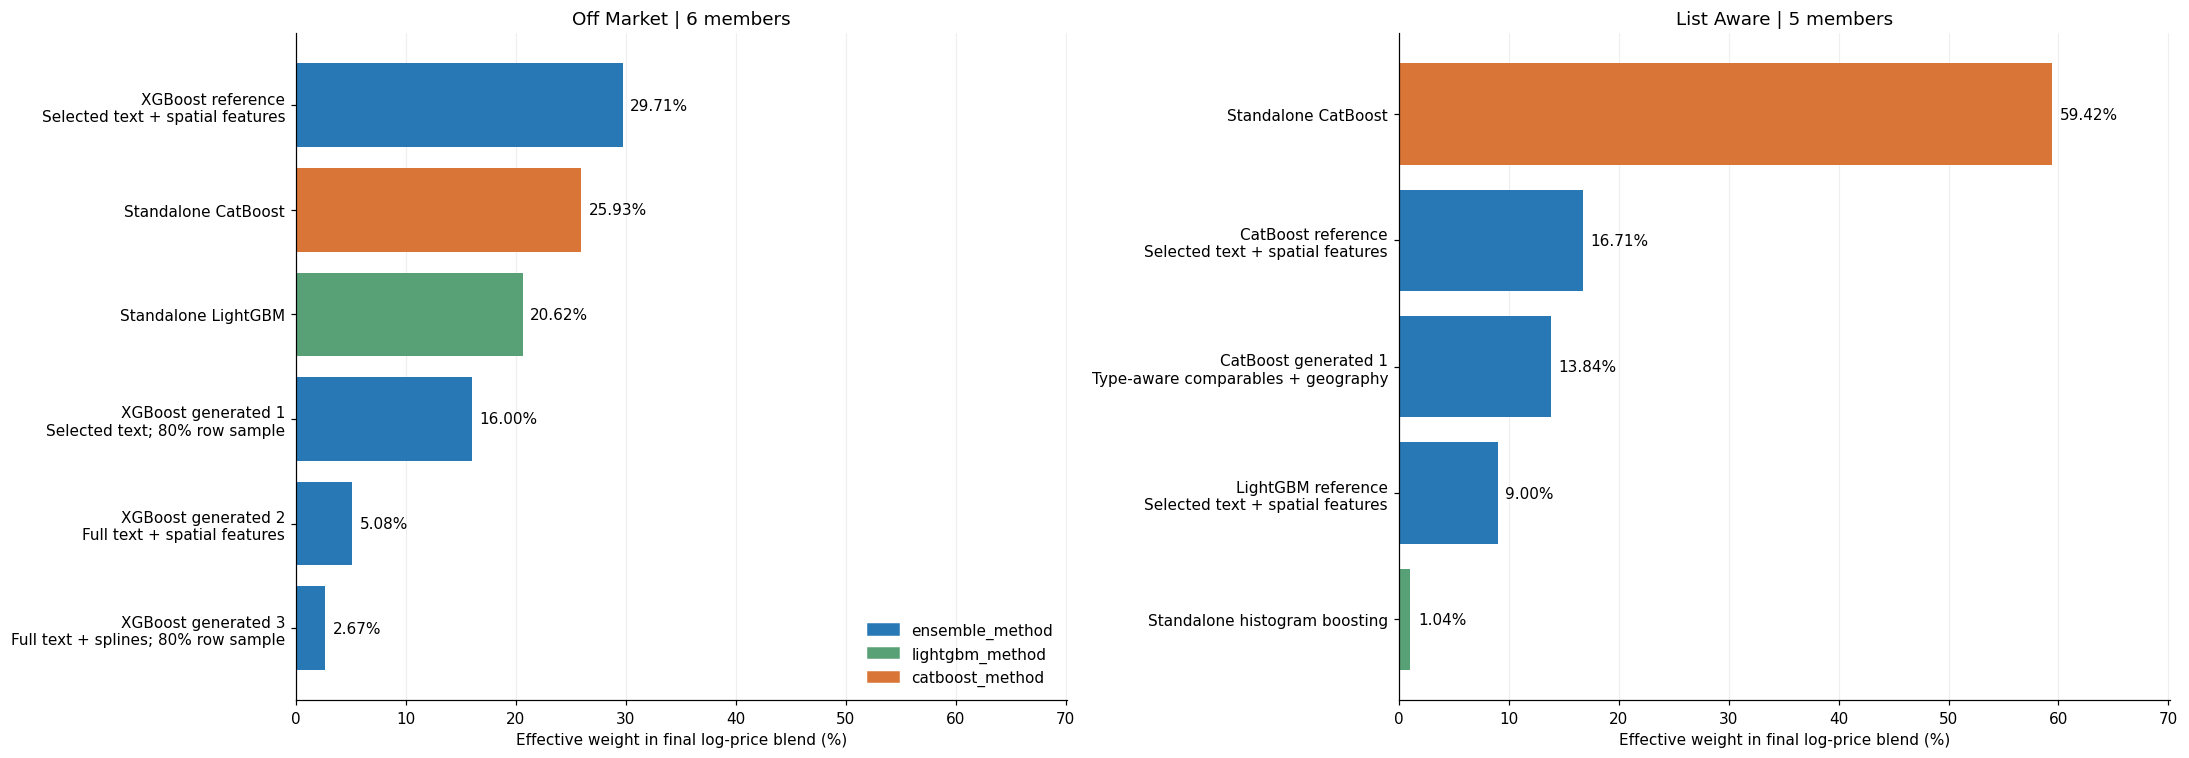

,track,contribution,member,display_name,weight_pct
0,off_market,ensemble_method,selected_47_splines_geo_reference,XGBoost reference\nSelected text + spatial fea...,29.7092
1,off_market,ensemble_method,g000_c001,XGBoost generated 1\nSelected text; 80% row sa...,15.9972
2,off_market,ensemble_method,g000_c002,XGBoost generated 2\nFull text + spatial features,5.0785
3,off_market,ensemble_method,g001_c001,XGBoost generated 3\nFull text + splines; 80% ...,2.6729
4,off_market,lightgbm_method,lightgbm_method (standalone),Standalone LightGBM,20.6170
5,off_market,catboost_method,catboost_method (standalone),Standalone CatBoost,25.9252
6,list_aware,ensemble_method,reference_catboost,CatBoost reference\nSelected text + spatial fe...,16.7083
7,list_aware,ensemble_method,reference_lightgbm,LightGBM reference\nSelected text + spatial fe...,8.9968
8,list_aware,ensemble_method,g001_c002_catboost,CatBoost generated 1\nType-aware comparables +...,13.8412
9,list_aware,lightgbm_method,lightgbm_method (standalone),Standalone histogram boosting,1.0382


In [ ]:
import json
from zipfile import ZipFile
from matplotlib.patches import Patch
import blended_model

settings = json.loads(blended_model.WEIGHTS_FILE.read_text(encoding='utf-8'))
if settings.get('factories') != list(blended_model.FACTORIES):
    raise ValueError('Frozen factories differ from blended_model.FACTORIES; restore the matching configuration.')
checkpoint_files = {'off_market': 'release_checkpoint.zip', 'list_aware': 'listaware_checkpoint.zip'}
contribution_colors = {'ensemble_method': '#2878B5', 'lightgbm_method': '#58A176', 'catboost_method': '#D97536'}
weight_rows = []
for track, checkpoint in checkpoint_files.items():
    team_weights = blended_model.validate_weights(settings['weights'][track], len(settings['factories']))
    for factory, team_weight in zip(settings['factories'], team_weights):
        contribution = factory.split('.')[0]
        if contribution == 'ensemble_method':
            with ZipFile(ROOT / 'colab_checkpoints' / checkpoint) as archive:
                internal = json.loads(archive.read('summary.json'))['effective_member_weights']
            internal_weights = blended_model.validate_weights(list(internal.values()), len(internal))
            for member, internal_weight in zip(internal, internal_weights):
                weight_rows.append(dict(track=track, contribution=contribution, member=member,
                    team_weight=team_weight, internal_weight=internal_weight,
                    effective_weight=team_weight * internal_weight))
        elif contribution in contribution_colors:
            weight_rows.append(dict(track=track, contribution=contribution,
                member=f'{contribution} (standalone)', team_weight=team_weight,
                internal_weight=1.0, effective_weight=team_weight))
        else:
            raise ValueError(f'Add a weight expansion rule for {factory}.')

member_weights = pd.DataFrame(weight_rows)
member_weights['weight_pct'] = 100 * member_weights.effective_weight
for track, expected_count in [('off_market', 6), ('list_aware', 5)]:
    rows = member_weights.loc[member_weights.track.eq(track)]
    if len(rows) != expected_count or not np.isclose(rows.effective_weight.sum(), 1):
        raise ValueError(f'Expected {expected_count} members with weights summing to 100% for {track}.')

# Readable chart labels; original checkpoint IDs remain in the exported table.
member_labels = {
    'selected_47_splines_geo_reference': 'XGBoost reference\nSelected text + spatial features',
    'g000_c001': 'XGBoost generated 1\nSelected text; 80% row sample',
    'g000_c002': 'XGBoost generated 2\nFull text + spatial features',
    'g001_c001': 'XGBoost generated 3\nFull text + splines; 80% row sample',
    'reference_catboost': 'CatBoost reference\nSelected text + spatial features',
    'reference_lightgbm': 'LightGBM reference\nSelected text + spatial features',
    'g001_c002_catboost': 'CatBoost generated 1\nType-aware comparables + geography',
    'lightgbm_method (standalone)': 'Standalone boosting contribution',
    'catboost_method (standalone)': 'Standalone CatBoost',
}
member_weights['display_name'] = member_weights.member.map(member_labels).fillna(member_weights.member)
member_weights.loc[(member_weights.track == 'off_market') &
                   (member_weights.contribution == 'lightgbm_method'), 'display_name'] = 'Standalone LightGBM'
member_weights.loc[(member_weights.track == 'list_aware') &
                   (member_weights.contribution == 'lightgbm_method'), 'display_name'] = 'Standalone histogram boosting'

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
upper = max(5, member_weights.weight_pct.max() * 1.18)
for ax, track in zip(axes, checkpoint_files):
    rows = member_weights.loc[member_weights.track.eq(track)].sort_values('effective_weight', ascending=False)
    bars = ax.barh(rows.display_name, rows.weight_pct, color=rows.contribution.map(contribution_colors))
    ax.bar_label(bars, labels=[f'{value:.2f}%' for value in rows.weight_pct], padding=5)
    ax.invert_yaxis()
    ax.set(xlim=(0, upper), xlabel='Effective weight in final log-price blend (%)',
           title=f'{track.replace("_", " ").title()} | {len(rows)} members')
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
axes[0].legend(handles=[Patch(color=color, label=name) for name, color in contribution_colors.items()],
               loc='lower right', frameon=False)
finish(fig, 'final_member_weights')
display(member_weights[['track', 'contribution', 'member', 'display_name', 'weight_pct']].round(4))
if SAVE_OUTPUTS:
    member_weights.to_csv(EXPORT_DIR / 'final_member_weights.csv', index=False)
